# Team 7 · Monday, part 2: can we make the search more accurate?

The first notebook (`autoencoder.ipynb`) showed the problem: at **64 × 64 px** the fine texture (brick joints, wood grain) is gone before the model sees it, so the codes group patches by **colour**, not material (precision@5 = 0.14, random = 0.077).

We try three kinds of fixes, always with the same split, seed, epochs and metric as the first notebook:

| Part | Idea | Setups |
|---|---|---|
| A | **More detail at the input** (same conv AE) | centre zoom (the labelled middle of the patch at 64 px), full patch at 128 px |
| B | **A pretrained network in front** of the autoencoder | ResNet-18 (ImageNet) turns each 224 px patch into 512 texture features; a small autoencoder compresses them to a 32-number code |
| C | **Regularisers** | weight decay, denoising (noise on the input), flips (augmentation), dropout on the code, L1 on the code |

The table at the end compares everything on **precision@5** (search quality, our main goal) and **ROC AUC** of the unusual score (building materials vs the 10 other MINC classes).

**Needs:** the parquet files in `data/minc-2500/data/` and the 64 px caches made by the first notebook. The first run decodes every patch once more (64 px zoom, 128 px, 224 px for ResNet) and caches the results in `data/` (git-ignored). ResNet-18 weights (45 MB) are downloaded by torchvision on first use.

In [1]:
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from PIL import Image
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18

AE_DIR = Path("..")
REPO_DIR = AE_DIR / ".."
DATA_DIR = REPO_DIR / "data"
MINC_DIR = DATA_DIR / "minc-2500" / "data"
FIG_DIR = AE_DIR / "figures"

RANDOM_STATE = 42
EPOCHS = 12
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"PyTorch {torch.__version__}, device: {DEVICE}")


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.14.1, device: mps


# 1. Data in four versions

The same patches as in the first notebook, in the same order:

- **64 px full patch** (the first notebook's cache): 362 px → 64 px, about 5.7 original pixels per model pixel.
- **64 px centre zoom:** only the middle half of the patch (181 px) → 64 px. 2× more detail, and MINC labels describe exactly the **centre** of the patch.
- **128 px full patch:** 2× more detail, 4× more pixels to process.
- **224 px for ResNet-18**, turned straight into 512 features (we keep only the features, not the images).

In [2]:
ALL_CLASSES = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather",
               "metal", "mirror", "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky",
               "stone", "tile", "wallpaper", "water", "wood"]
BUILDING = ["brick", "carpet", "ceramic", "glass", "metal", "mirror", "painted", "plastic",
            "polishedstone", "stone", "tile", "wallpaper", "wood"]
BUILDING_IDS = [ALL_CLASSES.index(c) for c in BUILDING]
OTHER_IDS = [i for i, c in enumerate(ALL_CLASSES) if c not in BUILDING]
remap = {orig: new for new, orig in enumerate(BUILDING_IDS)}

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def centre_square(image, fraction=1.0):
    # RGB, then the centre square; fraction 0.5 keeps the middle half (the "zoom")
    image = image.convert("RGB")
    w, h = image.size
    side = int(min(w, h) * fraction)
    left, top = (w - side) // 2, (h - side) // 2
    return image.crop((left, top, left + side, top + side))


def get_backbone():
    # ResNet-18 trained on ImageNet, without its last layer: image (224 px) -> 512 features
    net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    net.fc = nn.Identity()
    return net.eval().to(DEVICE)


@torch.no_grad()
def resnet_features(backbone, batch_u8):
    x = torch.from_numpy(np.stack(batch_u8)).permute(0, 3, 1, 2).float().div(255)
    x = (x - IMAGENET_MEAN) / IMAGENET_STD
    return backbone(x.to(DEVICE)).cpu().numpy()


def load_extra(split, label_ids, name):
    # One pass over the JPEGs: 64 px zoom, 128 px full, ResNet-18 features. Cached in data/.
    cache = DATA_DIR / f"minc_extra_{name}.npz"
    if cache.exists():
        d = np.load(cache)
        return {k: d[k] for k in d.files}
    start = time.time()
    files = sorted(MINC_DIR.glob(f"{split}-*.parquet"))
    df = (pl.scan_parquet(files)
          .select(pl.col("image").struct.field("bytes").alias("bytes"), pl.col("label"))
          .filter(pl.col("label").is_in(label_ids)).collect())
    backbone = get_backbone()
    zoom64, full128, feats, batch = [], [], [], []
    for b in df["bytes"]:
        square = centre_square(Image.open(io.BytesIO(b)))
        zoom64.append(np.asarray(centre_square(square, 0.5).resize((64, 64), Image.BILINEAR)))
        full128.append(np.asarray(square.resize((128, 128), Image.BILINEAR)))
        batch.append(np.asarray(square.resize((224, 224), Image.BILINEAR)))
        if len(batch) == 256:
            feats.append(resnet_features(backbone, batch)); batch = []
    if batch:
        feats.append(resnet_features(backbone, batch))
    out = {"zoom64": np.stack(zoom64), "full128": np.stack(full128),
           "feat": np.concatenate(feats).astype(np.float32), "y": df["label"].to_numpy()}
    np.savez(cache, **out)
    print(f"{name}: {len(df):,} patches in {time.time() - start:.0f} s -> {cache.name}")
    return out


def to_tensor(X_u8):
    return torch.from_numpy(X_u8).permute(0, 3, 1, 2).contiguous()


data = {}
for split, ids, name in [("train", BUILDING_IDS, "train"), ("validation", BUILDING_IDS, "val"),
                         ("test", BUILDING_IDS, "test"), ("test", OTHER_IDS, "test_other")]:
    base = np.load(DATA_DIR / f"minc64_{name}.npz")
    extra = load_extra(split, ids, name)
    assert (base["y"] == extra["y"]).all(), "patch order differs from the first notebook's cache"
    data[name] = {"full64": to_tensor(base["X"]), "zoom64": to_tensor(extra["zoom64"]),
                  "full128": to_tensor(extra["full128"]), "feat": torch.from_numpy(extra["feat"]),
                  "img64": base["X"]}

y_train = np.array([remap[v] for v in np.load(DATA_DIR / "minc64_train.npz")["y"]])
y_test = np.array([remap[v] for v in np.load(DATA_DIR / "minc64_test.npz")["y"]])
for name, d in data.items():
    print(f"{name:10s} " + " | ".join(f"{k} {tuple(v.shape)}" for k, v in d.items() if k != "img64"))

train      full64 (27625, 3, 64, 64) | zoom64 (27625, 3, 64, 64) | full128 (27625, 3, 128, 128) | feat (27625, 512)
val        full64 (1625, 3, 64, 64) | zoom64 (1625, 3, 64, 64) | full128 (1625, 3, 128, 128) | feat (1625, 512)
test       full64 (3250, 3, 64, 64) | zoom64 (3250, 3, 64, 64) | full128 (3250, 3, 128, 128) | feat (3250, 512)
test_other full64 (2500, 3, 64, 64) | zoom64 (2500, 3, 64, 64) | full128 (2500, 3, 128, 128) | feat (2500, 512)


Figure saved to ../figures/08_input_versions.png


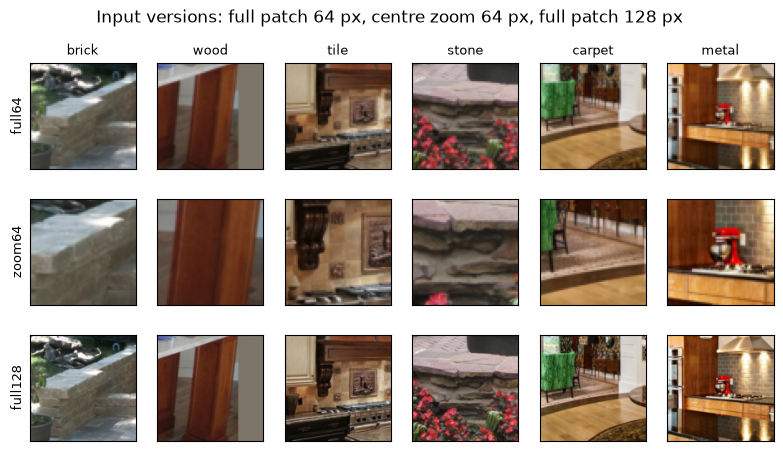

In [3]:
# What the model sees: the same 6 test patches in the three image versions
idx = [int(np.flatnonzero(y_test == BUILDING.index(m))[3]) for m in ["brick", "wood", "tile", "stone", "carpet", "metal"]]
fig, axes = plt.subplots(3, len(idx), figsize=(len(idx) * 1.6, 5))
for row, key in enumerate(["full64", "zoom64", "full128"]):
    for j, i in enumerate(idx):
        axes[row, j].imshow(data["test"][key][i].permute(1, 2, 0).numpy())
        axes[row, j].set_xticks([]); axes[row, j].set_yticks([])
        if row == 0:
            axes[row, j].set_title(BUILDING[y_test[i]], fontsize=9)
    axes[row, 0].set_ylabel(key, fontsize=9)
plt.suptitle("Input versions: full patch 64 px, centre zoom 64 px, full patch 128 px")
save_fig("08_input_versions")
plt.show()

# 2. Models, training with regularisers, evaluation

- `ConvAE(latent_dim, image_size)`: the conv AE of the first notebook. At 64 px it is **exactly** the same network; at 128 px it gets one more stride-2 convolution (128 → 64 → 32 → 16 → 8).
- `FeatureAE`: a small dense autoencoder on the 512 ResNet features: 512 → 256 → **32** → 256 → 512. ResNet-18 stays frozen; only the autoencoder is trained, still without labels.

**The regularisers** (all options of one training function):

| Option | What it does | Why it might help search |
|---|---|---|
| `weight_decay` | AdamW pulls weights towards 0 | smoother codes, less memorising of single patches |
| `noise_std` | adds Gaussian noise to the input, the target stays clean (**denoising AE**) | the code must describe structure, not pixel noise |
| `augment` | random horizontal and vertical flips | a texture flipped is the same material: codes should not care |
| `code_dropout` | drops random code numbers before the decoder | spreads information over all 32 numbers |
| `l1_code` | penalty on the size of the code (**sparse AE**) | each patch uses only a few numbers |

In [4]:
class ConvAE(nn.Module):
    def __init__(self, latent_dim=32, image_size=64):
        super().__init__()
        n_down = int(np.log2(image_size // 8))                     # 64 -> 3 steps, 128 -> 4 steps
        ch = [3, 32, 64, 128, 128, 128][:n_down + 1]
        enc = []
        for a, b in zip(ch[:-1], ch[1:]):
            enc += [nn.Conv2d(a, b, 4, stride=2, padding=1), nn.ReLU()]
        self.encoder = nn.Sequential(*enc, nn.Flatten(), nn.Linear(ch[-1] * 64, latent_dim))
        dec = [nn.Linear(latent_dim, ch[-1] * 64), nn.ReLU(), nn.Unflatten(1, (ch[-1], 8, 8))]
        rev = ch[::-1]
        for i, (a, b) in enumerate(zip(rev[:-1], rev[1:])):
            dec += [nn.ConvTranspose2d(a, b, 4, stride=2, padding=1),
                    nn.Sigmoid() if i == len(rev) - 2 else nn.ReLU()]
        self.decoder = nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))


class FeatureAE(nn.Module):
    def __init__(self, n_in=512, latent_dim=32, hidden=256):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n_in))

    def forward(self, x):
        return self.decoder(self.encoder(x))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


# Feature AE input: ResNet features standardised with the TRAINING mean and std (the server needs these two)
FEAT_MEAN = data["train"]["feat"].mean(0)
FEAT_STD = data["train"]["feat"].std(0) + 1e-6


def prepare(batch, kind):
    # uint8 images -> floats 0-1; features -> standardised
    if kind == "image":
        return batch.float().div(255)
    return (batch - FEAT_MEAN) / FEAT_STD


def flip_randomly(x):
    n = len(x)
    h = torch.rand(n, 1, 1, 1, device=x.device) < 0.5
    v = torch.rand(n, 1, 1, 1, device=x.device) < 0.5
    x = torch.where(h, x.flip(3), x)
    return torch.where(v, x.flip(2), x)


def train(model, X_train, X_val, kind="image", epochs=EPOCHS, lr=1e-3, batch_size=128,
          weight_decay=0.0, noise_std=0.0, augment=False, code_dropout=0.0, l1_code=0.0):
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)  # wd 0 = plain Adam
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(RANDOM_STATE))
    history, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (batch,) in loader:
            x = prepare(batch, kind).to(DEVICE)
            if augment and kind == "image":
                x = flip_randomly(x)
            x_in = x + noise_std * torch.randn_like(x) if noise_std else x
            if kind == "image" and noise_std:
                x_in = x_in.clamp(0, 1)
            code = model.encoder(x_in)
            code_used = nn.functional.dropout(code, code_dropout) if code_dropout else code
            loss = nn.functional.mse_loss(model.decoder(code_used), x)       # rebuild the CLEAN input
            if l1_code:
                loss = loss + l1_code * code.abs().mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
        history.append({"epoch": epoch, "train_loss": total / len(X_train),
                        "val_mse": errors(model, X_val, kind).mean()})
    return model, pd.DataFrame(history), time.time() - start


@torch.no_grad()
def errors(model, X, kind, batch_size=500):
    # Reconstruction error per item (the unusual score)
    model.eval()
    out = []
    for i in range(0, len(X), batch_size):
        x = prepare(X[i:i + batch_size], kind).to(DEVICE)
        out.append(((model(x) - x) ** 2).flatten(1).mean(1).cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def encode(model, X, kind, batch_size=500):
    model.eval()
    return torch.cat([model.encoder(prepare(X[i:i + batch_size], kind).to(DEVICE)).cpu()
                      for i in range(0, len(X), batch_size)]).numpy()


def precision_at_k(Z_gallery, y_gallery, Z_query, y_query, k=5):
    _, idx = NearestNeighbors(n_neighbors=k).fit(Z_gallery).kneighbors(Z_query)
    hits = y_gallery[idx] == y_query[:, None]
    return hits.mean(), hits.mean(axis=1)


rows, trained = [], {}


def run(name, part, make_model, key, kind="image", **reg):
    # Train one setup and add a row to the comparison table
    model, history, seconds = train(make_model(), data["train"][key], data["val"][key], kind, **reg)
    Z_tr, Z_te = encode(model, data["train"][key], kind), encode(model, data["test"][key], kind)
    p5, per_query = precision_at_k(Z_tr, y_train, Z_te, y_test)
    err_b, err_o = errors(model, data["test"][key], kind), errors(model, data["test_other"][key], kind)
    auc = roc_auc_score(np.r_[np.zeros(len(err_b)), np.ones(len(err_o))], np.r_[err_b, err_o])
    trained[name] = {"model": model, "key": key, "kind": kind, "history": history,
                     "Z_train": Z_tr, "Z_test": Z_te, "per_query": per_query}
    rows.append({"setup": name, "part": part, "parameters": n_params(model), "train time (s)": round(seconds),
                 "test MSE": err_b.mean() if kind == "image" else np.nan,
                 "precision@5": p5, "unusual AUC": auc})
    print(f"{name:45s} precision@5 {p5:.3f}  unusual AUC {auc:.3f}  ({seconds:.0f} s)")
    return model

# 3. Part A: more detail at the input

The baseline is re-trained here with the same code, so every row of the final table comes from the same training function.

In [5]:
run("baseline: conv AE 32, full patch 64 px", "A", lambda: ConvAE(32, 64), "full64")
run("conv AE 32, centre zoom 64 px", "A", lambda: ConvAE(32, 64), "zoom64")
run("conv AE 32, full patch 128 px", "A", lambda: ConvAE(32, 128), "full128")

baseline: conv AE 32, full patch 64 px        precision@5 0.145  unusual AUC 0.646  (180 s)
conv AE 32, centre zoom 64 px                 precision@5 0.149  unusual AUC 0.645  (173 s)
conv AE 32, full patch 128 px                 precision@5 0.144  unusual AUC 0.640  (673 s)


ConvAE(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): ReLU()
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=8192, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=8192, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(128, 8, 8))
    (3): ConvTranspose2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): ReLU()
    (7): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): ReLU()
    (9): ConvTranspose2d(32, 3,

# 4. Part B: a pretrained network in front

ResNet-18 was trained on 1.2 million ImageNet photos to recognise objects. Its first layers have learned to detect edges, grain, weave and repetition: exactly the texture we lose at 64 px. We use it **frozen** as a feature extractor (224 px in, 512 numbers out) and train our autoencoder on these features.

For reference we also measure the 512 raw features without any autoencoder: this shows how much the autoencoder's compression to 32 numbers costs.

In [6]:
p5_raw, _ = precision_at_k(prepare(data["train"]["feat"], "feat").numpy(), y_train,
                           prepare(data["test"]["feat"], "feat").numpy(), y_test)
print(f"reference: raw ResNet-18 features (512 numbers, no AE): precision@5 {p5_raw:.3f}")

FEAT_EPOCHS = 30            # the feature AE is tiny and fast: more epochs, still seconds
run("ResNet-18 + feature AE 32", "B", lambda: FeatureAE(), "feat", "feat", epochs=FEAT_EPOCHS, batch_size=256)

reference: raw ResNet-18 features (512 numbers, no AE): precision@5 0.424
ResNet-18 + feature AE 32                     precision@5 0.408  unusual AUC 0.671  (25 s)


FeatureAE(
  (encoder): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
  )
)

# 5. Part C: regularisers

Each regulariser alone, first on the pixel conv AE (64 px full patch, the deployed model), then the most useful ones on the ResNet feature AE.

In [7]:
conv = lambda: ConvAE(32, 64)
run("conv AE 64 px + weight decay 1e-4", "C", conv, "full64", weight_decay=1e-4)
run("conv AE 64 px + denoising (noise 0.1)", "C", conv, "full64", noise_std=0.1)
run("conv AE 64 px + flips (augmentation)", "C", conv, "full64", augment=True)
run("conv AE 64 px + code dropout 0.2", "C", conv, "full64", code_dropout=0.2)
run("conv AE 64 px + L1 on code 1e-3", "C", conv, "full64", l1_code=1e-3)

conv AE 64 px + weight decay 1e-4             precision@5 0.138  unusual AUC 0.648  (122 s)
conv AE 64 px + denoising (noise 0.1)         precision@5 0.141  unusual AUC 0.647  (94 s)
conv AE 64 px + flips (augmentation)          precision@5 0.138  unusual AUC 0.646  (89 s)
conv AE 64 px + code dropout 0.2              precision@5 0.140  unusual AUC 0.662  (92 s)
conv AE 64 px + L1 on code 1e-3               precision@5 0.145  unusual AUC 0.646  (92 s)


ConvAE(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=8192, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=8192, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(128, 8, 8))
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): ReLU()
    (7): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

In [8]:
feat = lambda: FeatureAE()
fe = dict(kind="feat", epochs=FEAT_EPOCHS, batch_size=256)
run("ResNet-18 + feature AE + weight decay 1e-4", "C", feat, "feat", weight_decay=1e-4, **fe)
run("ResNet-18 + feature AE + denoising (noise 0.5)", "C", feat, "feat", noise_std=0.5, **fe)
run("ResNet-18 + feature AE + code dropout 0.2", "C", feat, "feat", code_dropout=0.2, **fe)
run("ResNet-18 + feature AE + denoising + weight decay", "C", feat, "feat", noise_std=0.5, weight_decay=1e-4, **fe)

ResNet-18 + feature AE + weight decay 1e-4    precision@5 0.410  unusual AUC 0.671  (12 s)
ResNet-18 + feature AE + denoising (noise 0.5) precision@5 0.414  unusual AUC 0.673  (12 s)
ResNet-18 + feature AE + code dropout 0.2     precision@5 0.399  unusual AUC 0.675  (13 s)
ResNet-18 + feature AE + denoising + weight decay precision@5 0.414  unusual AUC 0.673  (12 s)


FeatureAE(
  (encoder): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
  )
)

# 6. Results

In [9]:
table = pd.DataFrame(rows).set_index("setup")
table.loc["reference: raw ResNet-18 features, no AE"] = {"part": "B", "parameters": 0, "train time (s)": 0,
                                                         "test MSE": np.nan, "precision@5": p5_raw, "unusual AUC": np.nan}
table.to_csv(AE_DIR / "results_improvements.csv")
base = table.loc["baseline: conv AE 32, full patch 64 px", "precision@5"]
table["vs baseline"] = table["precision@5"] / base
table.sort_values("precision@5", ascending=False)

,part,parameters,train time (s),test MSE,precision@5,unusual AUC,vs baseline
setup,,,,,,,
"reference: raw ResNet-18 features, no AE",B,0,0,NaN,0.4243,NaN,2.9241
ResNet-18 + feature AE + denoising + weight decay,C,279584,12,NaN,0.4138,0.6728,2.8520
ResNet-18 + feature AE + denoising (noise 0.5),C,279584,12,NaN,0.4135,0.6729,2.8499
ResNet-18 + feature AE + weight decay 1e-4,C,279584,12,NaN,0.4097,0.6710,2.8236
ResNet-18 + feature AE 32,B,279584,25,NaN,0.4076,0.6709,2.8087
ResNet-18 + feature AE + code dropout 0.2,C,279584,13,NaN,0.3993,0.6747,2.7515
"conv AE 32, centre zoom 64 px",A,863587,173,0.0078,0.1493,0.6448,1.0288
"baseline: conv AE 32, full patch 64 px",A,863587,180,0.0102,0.1451,0.6463,1.0000
conv AE 64 px + L1 on code 1e-3,C,863587,92,0.0103,0.1447,0.6463,0.9975


Figure saved to ../figures/09_improvements_precision.png


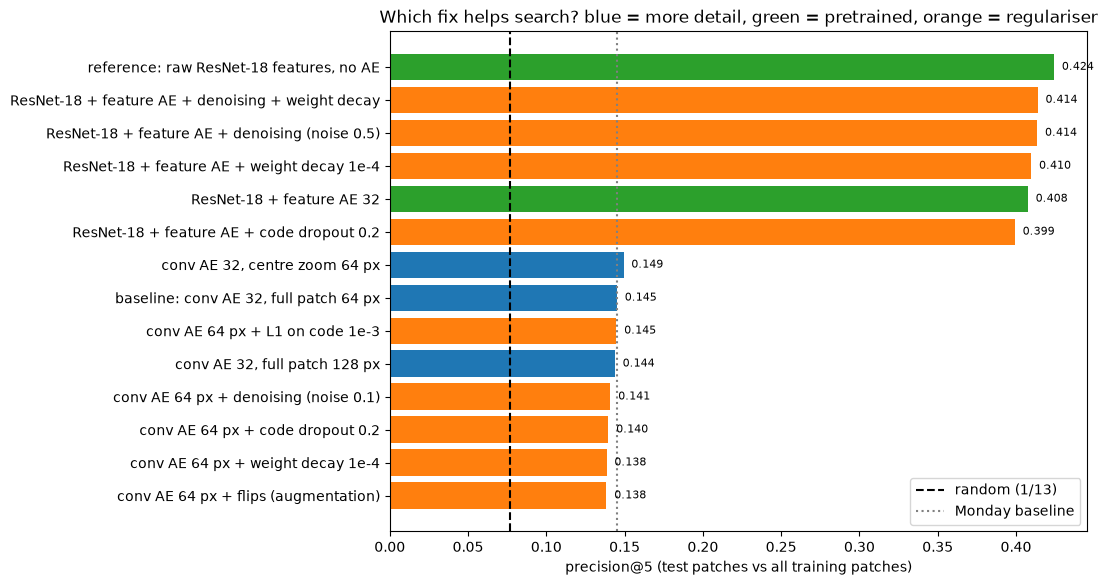

In [10]:
t = table.sort_values("precision@5")
colours = t["part"].map({"A": "tab:blue", "B": "tab:green", "C": "tab:orange"})
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(t.index, t["precision@5"], color=colours)
ax.axvline(1 / 13, color="black", linestyle="--", label="random (1/13)")
ax.axvline(base, color="grey", linestyle=":", label="Monday baseline")
for i, v in enumerate(t["precision@5"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("precision@5 (test patches vs all training patches)")
ax.set_title("Which fix helps search? blue = more detail, green = pretrained, orange = regulariser")
ax.legend(loc="lower right")
save_fig("09_improvements_precision")
plt.show()

best autoencoder setup: ResNet-18 + feature AE + denoising + weight decay
Figure saved to ../figures/10_improvements_per_material.png


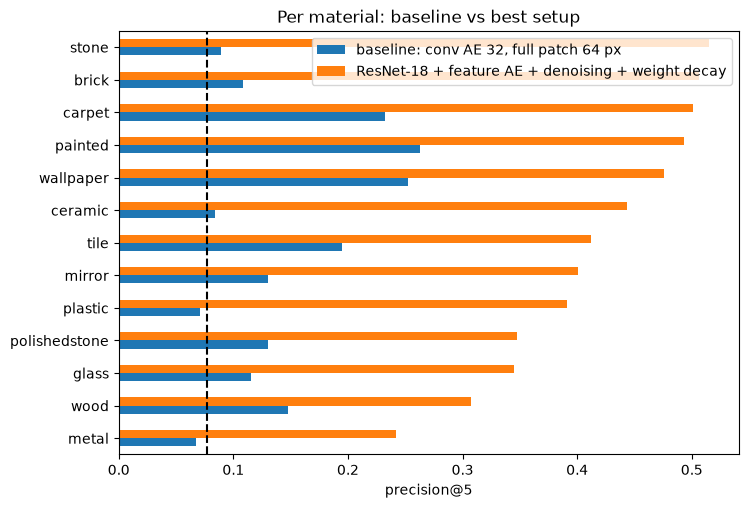

,brick,carpet,ceramic,glass,metal,mirror,painted,plastic,polishedstone,stone,tile,wallpaper,wood
"baseline: conv AE 32, full patch 64 px",0.1088,0.2320,0.0840,0.1152,0.0672,0.1304,0.2632,0.0712,0.1304,0.0896,0.1944,0.2520,0.1480
ResNet-18 + feature AE + denoising + weight decay,0.5064,0.5008,0.4432,0.3448,0.2416,0.4008,0.4936,0.3912,0.3472,0.5152,0.4120,0.4760,0.3072


In [11]:
# Per material: Monday baseline vs the best setup
BEST = table.drop("reference: raw ResNet-18 features, no AE")["precision@5"].idxmax()
print("best autoencoder setup:", BEST)
per = pd.DataFrame({
    name: pd.Series(trained[name]["per_query"]).groupby(y_test).mean().set_axis(BUILDING)
    for name in ["baseline: conv AE 32, full patch 64 px", BEST]})
ax = per.sort_values(BEST).plot.barh(figsize=(8, 5.5))
ax.axvline(1 / 13, color="black", linestyle="--")
ax.set_xlabel("precision@5"); ax.set_title("Per material: baseline vs best setup")
save_fig("10_improvements_per_material")
plt.show()
per.T

Figure saved to ../figures/11_improvements_similarity.png


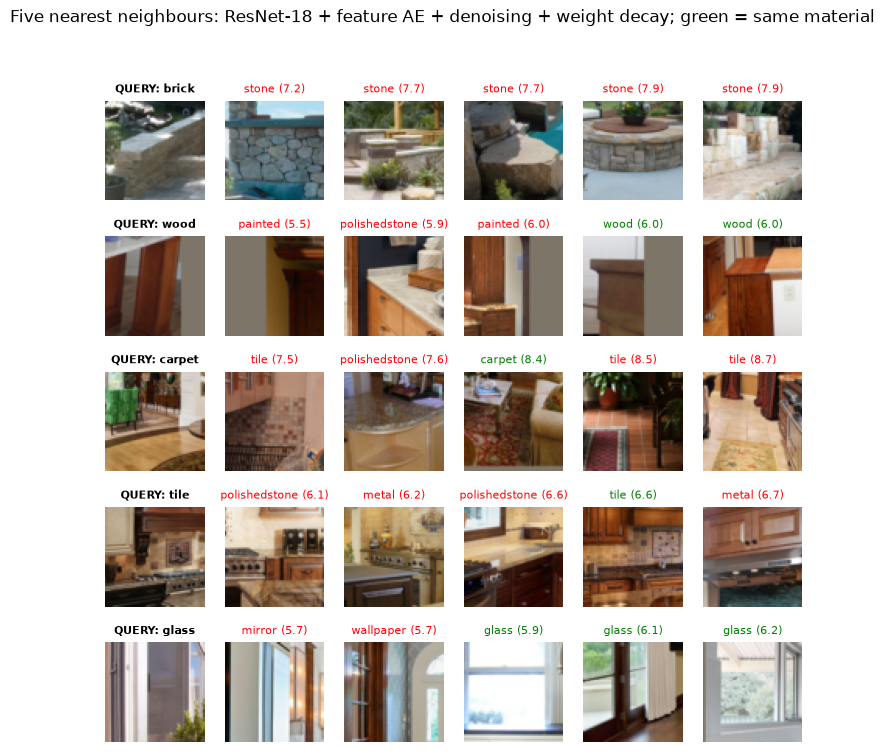

In [12]:
# Proof figure for the best setup (thumbnails are the 64 px patches)
best = trained[BEST]
index = NearestNeighbors(n_neighbors=5).fit(best["Z_train"])
SHOW = ["brick", "wood", "carpet", "tile", "glass"]
queries = [int(np.flatnonzero(y_test == BUILDING.index(m))[3]) for m in SHOW]
dist, nbr = index.kneighbors(best["Z_test"][queries])
fig, axes = plt.subplots(len(SHOW), 6, figsize=(9, 1.7 * len(SHOW)))
for r, q in enumerate(queries):
    axes[r, 0].imshow(data["test"]["img64"][q])
    axes[r, 0].set_title(f"QUERY: {BUILDING[y_test[q]]}", fontsize=8, fontweight="bold")
    for c in range(5):
        i = nbr[r, c]
        axes[r, c + 1].imshow(data["train"]["img64"][i])
        axes[r, c + 1].set_title(f"{BUILDING[y_train[i]]} ({dist[r, c]:.1f})", fontsize=8,
                                 color="green" if y_train[i] == y_test[q] else "red")
    for a in axes[r]:
        a.axis("off")
plt.suptitle(f"Five nearest neighbours: {BEST}; green = same material")
save_fig("11_improvements_similarity")
plt.show()

# 7. What we conclude

**✍️ Write this yourselves after reading the table.** Questions to answer:
- Which helps more: more pixels (part A), a pretrained network (part B) or regularisers (part C)? By how much over 0.14?
- Which regularisers helped, which made no difference, which hurt? Why might that be?
- Which materials improved most with the best setup? Are metal, glass and plastic still the weakest?
- What does the unusual score (AUC) do with the pretrained features?
- **Deployment cost:** the ResNet setup needs a 45 MB ONNX file instead of 3.5 MB, and 224 px input. Is that fine for Render's free server?
- Honesty note for the README: ResNet-18 was trained **with labels** (ImageNet objects, not materials). Our autoencoder still never sees MINC labels.